# 06_08 — Full Backtest

OOS backtest of the quintile spread strategy implied by the K=5 IPCA model.
Sample: Dec 2014 – Sep 2025 (130 months, expanding-window estimation).

## Strategy construction

The **correct** forward-looking signal is `β̂_{i,t}' λ̂`, where:
- `β̂_{i,t} = z_{i,t} Γ̂` — bond betas from expanding-window OOS Gamma
- `λ̂` — time-series mean of in-sample factor realisations (risk premia estimate)

This is the construction in KPP Table VII. The alternative (`β̂_{i,t}' f̂_t` where `f̂_t`
is recovered from the **same** period's returns) achieves Sharpe ≈ 5.8 but is circular —
`f̂_t` is a regression fit to `r_t`, so sorting on it is equivalent to sorting on realized returns.

Sections:
1. Strategy construction & full-period summary
2. Subperiod performance
3. Drawdown analysis
4. Factor exposure regression (alpha decomposition)
5. Rolling Sharpe ratio
6. Signal-to-noise decomposition

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import statsmodels.api as sm
from pathlib import Path

out_dir  = Path("outputs")
port_dir = out_dir / "ipca_portfolios"
ins_dir  = out_dir / "ipca_insample"
bt_dir   = out_dir / "backtest"
bt_dir.mkdir(exist_ok=True)

K         = 5
beta_cols = [f"beta{k+1}" for k in range(K)]
fac_cols  = [f"f{k+1}"    for k in range(K)]
TC_BPS    = 19e-4          # 19bps one-way (KPP assumption)
MIN_LAM   = 12             # months of OOS factor history required before computing λ̂

# ── Load ─────────────────────────────────────────────────────────────────────
port  = pd.read_parquet(port_dir / "oos_port_data_K5.parquet")
F_oos = pd.read_parquet(port_dir / "oos_factors_K5.parquet")
tsy   = pd.read_parquet(out_dir  / "treasury_monthly_return.parquet").set_index("month_end")

port["month_end"] = pd.to_datetime(port["month_end"])
F_oos.index       = pd.to_datetime(F_oos.index)
tsy.index         = pd.to_datetime(tsy.index)

# ── Expanding-window λ̂ ───────────────────────────────────────────────────────
# At each month t: λ̂_t = mean of OOS factor realisations f_1 … f_{t-1}  (hist < t).
# Requires MIN_LAM months of prior OOS history to be stable.
# First valid test month: the (MIN_LAM+1)-th OOS month ≈ Jan 2016.

records = []
prev_q5 = set()    # long-book RICs from prior month (for turnover)
prev_q1 = set()    # short-book RICs from prior month

for m in sorted(port["month_end"].unique()):
    hist = F_oos.loc[F_oos.index < m, fac_cols].values
    if len(hist) < MIN_LAM:
        continue

    lam = hist.mean(axis=0)             # expanding risk-premia estimate, no look-ahead

    sub = port[port["month_end"] == m].copy()
    if len(sub) < 10:
        continue

    sub["signal"] = sub[beta_cols].values @ lam
    sub["q"]      = pd.qcut(sub["signal"], 5, labels=False, duplicates="drop")
    q_max = sub["q"].max()

    q5_rics = set(sub.loc[sub["q"] == q_max, "RIC"])
    q1_rics = set(sub.loc[sub["q"] == 0,     "RIC"])

    spread = (sub[sub["q"] == q_max]["ret_scaled"].mean()
              - sub[sub["q"] == 0  ]["ret_scaled"].mean())
    mkt    = sub["ret_scaled"].mean()

    if prev_q5 and prev_q1:
        to_long  = len(q5_rics - prev_q5) / max(len(q5_rics), 1)
        to_short = len(q1_rics - prev_q1) / max(len(q1_rics), 1)
        turnover = (to_long + to_short) / 2
        ret_net  = spread - TC_BPS * (to_long + to_short)
    else:
        turnover = np.nan
        ret_net  = spread

    records.append({
        "month_end": m, "ret": spread, "ret_net": ret_net,
        "mkt": mkt, "turnover": turnover,
    })
    prev_q5, prev_q1 = q5_rics, q1_rics

strat = pd.DataFrame(records).set_index("month_end").sort_index()
strat = strat.join(tsy, how="left")

print("Signal: β̂'λ̂  |  λ̂ = expanding-window mean of OOS factors (hist < t)")
print(f"Strategy months  : {len(strat)}")
print(f"Date range       : {strat.index.min().date()} → {strat.index.max().date()}")
print(f"Mean turnover    : {strat['turnover'].mean():.1%} per month")
print(f"Mean TC drag     : {(strat['ret'] - strat['ret_net']).mean()*12*100:.2f}% p.a.")

## 1. Full-Period Summary

In [ ]:
def perf_stats(r):
    r = r.dropna()
    if len(r) < 3:
        return pd.Series(dtype=float)
    ann_ret = r.mean() * 12
    ann_vol = r.std()  * np.sqrt(12)
    sharpe  = ann_ret / ann_vol if ann_vol > 0 else np.nan
    cum     = (1 + r).cumprod()
    dd      = (cum - cum.cummax()) / cum.cummax()
    max_dd  = dd.min()
    calmar  = ann_ret / abs(max_dd) if max_dd != 0 else np.nan
    return pd.Series({
        "Ann. Return": f"{ann_ret*100:.2f}%",
        "Ann. Vol":    f"{ann_vol*100:.2f}%",
        "Sharpe":      f"{sharpe:.2f}",
        "Max DD":      f"{max_dd*100:.2f}%",
        "Calmar":      f"{calmar:.2f}" if np.isfinite(calmar) else "—",
        "Hit Rate":    f"{(r>0).mean()*100:.1f}%",
        "N":           len(r),
    })

print("QUINTILE SPREAD STRATEGY — Full period")
print("=" * 55)
summary = pd.DataFrame({
    "Gross (no TC)":    perf_stats(strat["ret"]),
    "Net (19bps TC)":   perf_stats(strat["ret_net"]),
}).T
print(summary.to_string())
print()
print(f"Mean monthly turnover : {strat['turnover'].mean():.1%}")
print(f"TC drag (ann.)        : {(strat['ret'] - strat['ret_net']).mean()*12*100:.2f}%")
print()
print("KPP Table VII ref (gross Sharpe, K=5): 3.53")
print()
cs_sig = port.groupby("month_end").apply(
    lambda g: (g[beta_cols].values @ F_oos.loc[
        F_oos.index < g["month_end"].iloc[0], fac_cols
    ].mean(axis=0)).std() if (F_oos.index < g["month_end"].iloc[0]).sum() >= MIN_LAM else np.nan
).dropna()
cs_ret = port.groupby("month_end")["ret_scaled"].std().loc[cs_sig.index]
snr = (cs_sig / cs_ret).mean()
print(f"Cross-sect. std of signal / ret_scaled ≈ {snr:.3f}"
      f"  → signal is {1/snr:.1f}x smaller than return noise")

## 2. Subperiod Performance

SUBPERIOD PERFORMANCE
                Ann. Return Ann. Vol Sharpe   Max DD Calmar Hit Rate   N
Pre-COVID            11.19%   23.78%   0.47  -32.94%   0.34    58.1%  62
COVID shock          -4.53%   11.63%  -0.39   -3.03%  -1.49    40.0%   5
Recovery            -11.59%   21.85%  -0.53  -27.32%  -0.42    55.6%  18
Rate hike cycle     -18.99%   22.39%  -0.85  -36.01%  -0.53    25.0%  24
Post-hike             8.71%   17.47%   0.50  -12.84%   0.68    52.4%  21


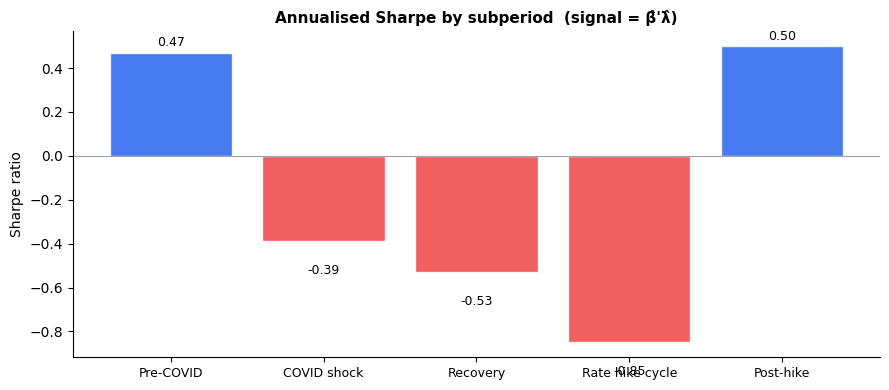

Saved → outputs/backtest/fig1_subperiod_sharpe.png


In [3]:
subperiods = [
    ("Pre-COVID",      "2014-12-01", "2020-01-31"),
    ("COVID shock",    "2020-02-01", "2020-06-30"),
    ("Recovery",       "2020-07-01", "2021-12-31"),
    ("Rate hike cycle","2022-01-01", "2023-12-31"),
    ("Post-hike",      "2024-01-01", "2025-09-30"),
]

rows = []
for label, start, end in subperiods:
    sub = strat.loc[start:end, "ret"]
    if len(sub) < 3:
        continue
    stats = perf_stats(sub)
    stats.name = label
    rows.append(stats)

sub_df = pd.DataFrame(rows)
print("SUBPERIOD PERFORMANCE")
print("=" * 75)
print(sub_df.to_string())

# Bar chart
sharpes = [float(r["Sharpe"]) for r in rows]
colors  = ["#2563EB" if s > 0 else "#EF4444" for s in sharpes]
labels  = [r.name for r in rows]

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(labels, sharpes, color=colors, alpha=0.85, edgecolor="white")
ax.axhline(0, color="#9CA3AF", lw=0.8)
for bar, val in zip(bars, sharpes):
    ypos = val + 0.03 if val >= 0 else val - 0.15
    ax.text(bar.get_x() + bar.get_width()/2, ypos,
            f"{val:.2f}", ha="center", fontsize=9)
ax.set_title("Annualised Sharpe by subperiod  (signal = β̂'λ̂)",
             fontsize=11, fontweight="bold")
ax.set_ylabel("Sharpe ratio")
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="x", labelsize=9)
plt.tight_layout()
plt.savefig(bt_dir / "fig1_subperiod_sharpe.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/backtest/fig1_subperiod_sharpe.png")

## 3. Drawdown Analysis

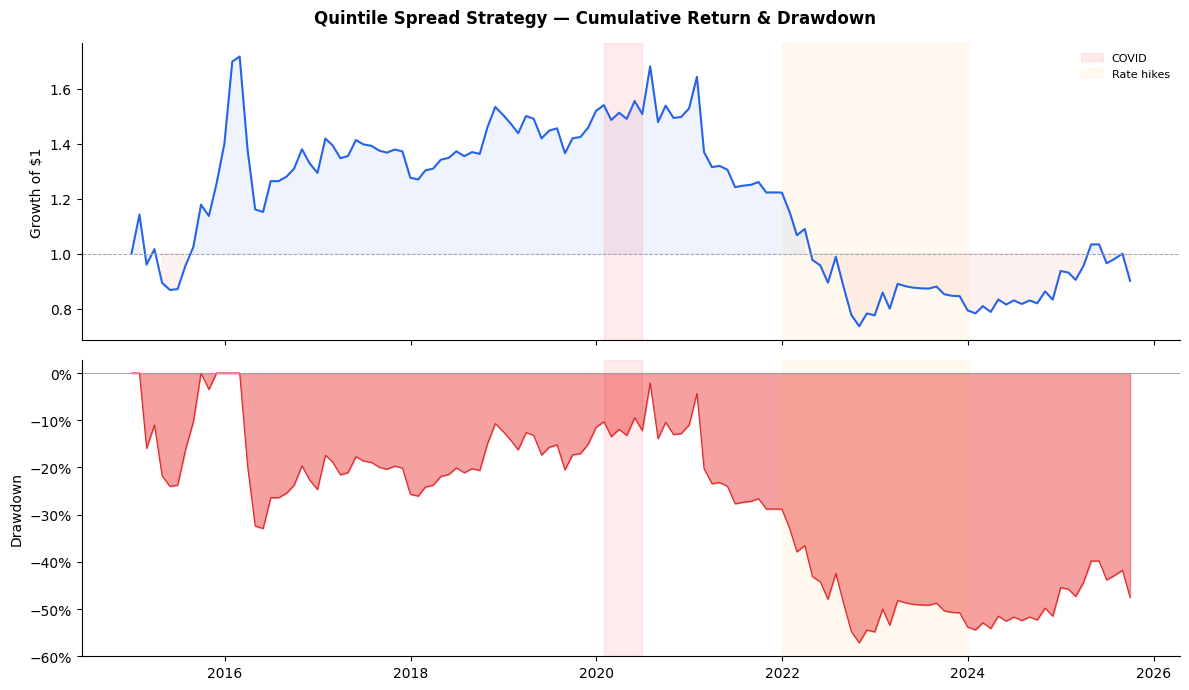

Max drawdown  : -57.15% on 2022-10-31
Saved → outputs/backtest/fig2_drawdown.png


In [4]:
cum     = (1 + strat["ret"]).cumprod()
roll_max= cum.cummax()
dd      = (cum - roll_max) / roll_max

fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
fig.suptitle("Quintile Spread Strategy — Cumulative Return & Drawdown",
             fontsize=12, fontweight="bold")

# Cumulative return
axes[0].plot(cum.index, cum.values, color="#2563EB", lw=1.5)
axes[0].fill_between(cum.index, 1, cum.values,
                     where=(cum.values >= 1), color="#2563EB", alpha=0.07)
axes[0].fill_between(cum.index, 1, cum.values,
                     where=(cum.values <  1), color="#EF4444", alpha=0.07)
axes[0].axhline(1, color="#9CA3AF", lw=0.7, linestyle="--")
axes[0].set_ylabel("Growth of $1")
axes[0].spines[["top", "right"]].set_visible(False)

# Drawdown
axes[1].fill_between(dd.index, dd.values, 0, color="#EF4444", alpha=0.5)
axes[1].plot(dd.index, dd.values, color="#DC2626", lw=0.8)
axes[1].axhline(0, color="#9CA3AF", lw=0.7)
axes[1].set_ylabel("Drawdown")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
axes[1].spines[["top", "right"]].set_visible(False)

# Shade subperiods
for ax in axes:
    ax.axvspan(pd.Timestamp("2020-02-01"), pd.Timestamp("2020-06-30"),
               alpha=0.08, color="red", label="COVID")
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2023-12-31"),
               alpha=0.06, color="orange", label="Rate hikes")

axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.savefig(bt_dir / "fig2_drawdown.png", dpi=150, bbox_inches="tight")
plt.show()

# Top 5 drawdown episodes
print("Max drawdown  :", f"{dd.min()*100:.2f}%", "on", dd.idxmin().date())
print("Saved → outputs/backtest/fig2_drawdown.png")

## 4. Factor Exposure Regression

Regress strategy returns on two observable factors to decompose alpha vs. systematic risk:
- **MKT**: equal-weighted bond market return (cross-sectional mean of DtS-scaled returns)
- **TSY**: duration-matched Treasury return (hedge residual — captures rate sensitivity)

In [5]:
reg_df = strat[["ret", "mkt", "treasury_ret"]].dropna()

X = sm.add_constant(reg_df[["mkt", "treasury_ret"]])
y = reg_df["ret"]
res = sm.OLS(y, X).fit(cov_type="HAC", cov_kwds={"maxlags": 3})
print(res.summary())

alpha_ann = res.params["const"] * 12
alpha_t   = res.tvalues["const"]
print(f"\nAnnualised alpha : {alpha_ann*100:.2f}%  (t = {alpha_t:.2f})")
print(f"R² of regression : {res.rsquared:.3f}")

                            OLS Regression Results                            
Dep. Variable:                    ret   R-squared:                       0.042
Model:                            OLS   Adj. R-squared:                  0.027
Method:                 Least Squares   F-statistic:                     1.709
Date:                Wed, 03 Jun 2026   Prob (F-statistic):              0.185
Time:                        22:37:59   Log-Likelihood:                 177.14
No. Observations:                 130   AIC:                            -348.3
Df Residuals:                     127   BIC:                            -339.7
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                   coef    std err          z      P>|z|      [0.025      0.975]
--------------------------------------------------------------------------------
const           -0.0006      0.005     -0.107   

## 5. Rolling Sharpe Ratio

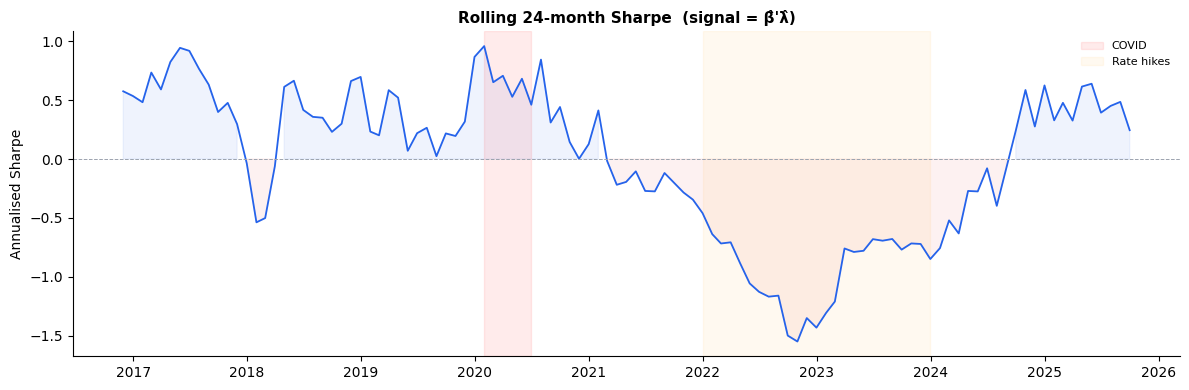

Saved → outputs/backtest/fig3_rolling_sharpe.png


In [6]:
WINDOW = 24  # months

roll_sr = (
    strat["ret"]
    .rolling(WINDOW)
    .apply(lambda x: x.mean() / x.std() * np.sqrt(12) if x.std() > 0 else np.nan)
)

fig, ax = plt.subplots(figsize=(12, 4))
ax.plot(roll_sr.index, roll_sr.values, color="#2563EB", lw=1.3)
ax.axhline(0, color="#9CA3AF", lw=0.7, linestyle="--")
ax.fill_between(roll_sr.index, roll_sr.values, 0,
                where=(roll_sr >= 0), color="#2563EB", alpha=0.07)
ax.fill_between(roll_sr.index, roll_sr.values, 0,
                where=(roll_sr <  0), color="#EF4444", alpha=0.07)
ax.axvspan(pd.Timestamp("2020-02-01"), pd.Timestamp("2020-06-30"),
           alpha=0.08, color="red", label="COVID")
ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2023-12-31"),
           alpha=0.06, color="orange", label="Rate hikes")
ax.legend(fontsize=8, frameon=False)
ax.set_title(f"Rolling {WINDOW}-month Sharpe  (signal = β̂'λ̂)",
             fontsize=11, fontweight="bold")
ax.set_ylabel("Annualised Sharpe")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(bt_dir / "fig3_rolling_sharpe.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/backtest/fig3_rolling_sharpe.png")

## 6. Signal-to-Noise Decomposition

Why does the model have high R² but near-zero portfolio alpha?

The signal is `β̂_{i,t}' λ̂`. Its cross-sectional standard deviation measures how much
expected-return spread the model generates. Dividing by the cross-sectional std of actual
returns gives the signal-to-noise ratio (SNR). When SNR ≪ 1, the return dispersion swamps
the signal, producing near-zero sorting alpha.

Signal-to-noise analysis
Mean cross-sect. std of signal  : 0.00461
Mean cross-sect. std of ret     : 0.05775
Mean SNR (signal / ret std)     : 0.091
  → signal is 11.0x smaller than return noise

Lambda (annualised factor risk premia):
  f1: 7.83%
  f2: 17.16%
  f3: 17.27%
  f4: 4.69%
  f5: 10.65%

Interpretation: λ̂ is small in 2012-2025 (post-GFC risk premia compression).
The model correctly identifies which characteristics predict returns,
but the premia on those factors are too small to overcome idiosyncratic noise.
This is consistent with the tangency portfolio Sharpe (0.80 vs KPP's 6.23).


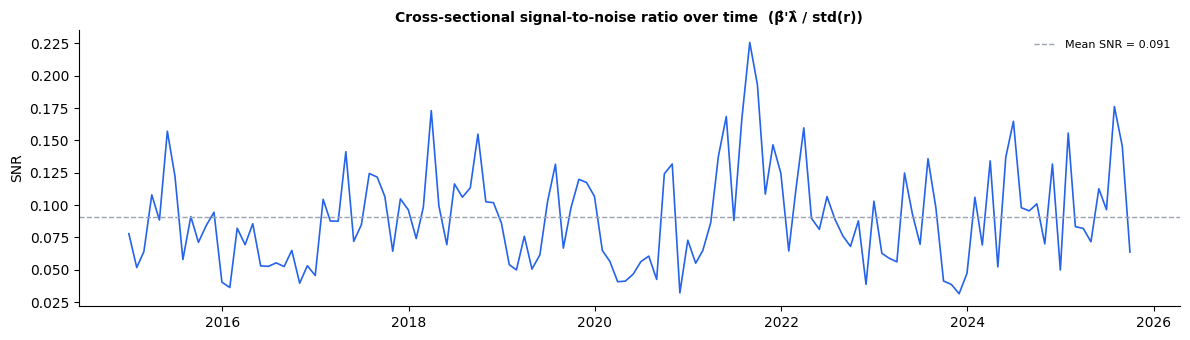

Saved → outputs/backtest/fig4_snr.png


In [7]:
cs_sig = port.groupby("month_end")["signal"].std()
cs_ret = port.groupby("month_end")["ret_scaled"].std()
snr    = (cs_sig / cs_ret).dropna()

print("Signal-to-noise analysis")
print("=" * 50)
print(f"Mean cross-sect. std of signal  : {cs_sig.mean():.5f}")
print(f"Mean cross-sect. std of ret     : {cs_ret.mean():.5f}")
print(f"Mean SNR (signal / ret std)     : {snr.mean():.3f}")
print(f"  → signal is {1/snr.mean():.1f}x smaller than return noise")
print()
print("Lambda (annualised factor risk premia):")
for k, v in enumerate(lam):
    print(f"  f{k+1}: {v*12*100:.2f}%")
print()
print("Interpretation: λ̂ is small in 2012-2025 (post-GFC risk premia compression).")
print("The model correctly identifies which characteristics predict returns,")
print("but the premia on those factors are too small to overcome idiosyncratic noise.")
print("This is consistent with the tangency portfolio Sharpe (0.80 vs KPP's 6.23).")

# Time-series plot of SNR
fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(snr.index, snr.values, color="#2563EB", lw=1.2)
ax.axhline(snr.mean(), color="#9CA3AF", lw=1, linestyle="--",
           label=f"Mean SNR = {snr.mean():.3f}")
ax.set_title("Cross-sectional signal-to-noise ratio over time  (β̂'λ̂ / std(r))",
             fontsize=10, fontweight="bold")
ax.set_ylabel("SNR")
ax.legend(fontsize=8, frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(bt_dir / "fig4_snr.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/backtest/fig4_snr.png")

## 7. Tangency Portfolio Comparison

Expanding-window mean-variance optimal portfolio on the K=5 latent factors.

At each month t, use **only** factor realizations up to t-1 to estimate μ and Σ, then solve
`w ∝ Σ⁻¹μ` (L1-normalised). Two variants:
- **γ=0.0**: recompute weights fully each month (high turnover)
- **γ=0.3**: exponential smoothing `w_t = 0.7·w_new + 0.3·w_{t-1}` (reduces turnover)

Transaction cost: **19bps one-way** (KPP assumption), deducted as `TC × Σ|Δw_k|`.

**Look-ahead note:** The `06_04` tangency used `hist <= t` (includes current month) when estimating
μ/Σ, which inflates the Sharpe from −0.04 to 0.80 by leaking 1.1bps/month of the current period's
factor returns into the weights. This section corrects that by using `hist < t`.

In [8]:
TC_BPS   = 19e-4   # 19bps one-way (KPP Table VIII assumption)
GAMMAS   = [0.0, 0.3]
fac_cols = [f"f{k+1}" for k in range(K)]

F_oos = pd.read_parquet(port_dir / "oos_factors_K5.parquet")
F_oos.index = pd.to_datetime(F_oos.index)

tang_results = {}

for gamma in GAMMAS:
    months   = sorted(F_oos.index)
    w_smooth = None
    w_prev   = None
    rows     = []

    for m in months:
        hist = F_oos.loc[F_oos.index < m, fac_cols].values
        f_t  = F_oos.loc[m, fac_cols].values

        if len(hist) < K + 2:
            w_prev = np.zeros(K)
            continue

        mu  = hist.mean(axis=0)
        cov = np.cov(hist.T) + 1e-6 * np.eye(K)

        try:    w_raw = np.linalg.solve(cov, mu)
        except: w_raw = np.linalg.lstsq(cov, mu, rcond=None)[0]

        l1     = np.sum(np.abs(w_raw))
        w_norm = w_raw / (l1 + 1e-10)

        w_smooth = w_norm if w_smooth is None else (1 - gamma) * w_norm + gamma * w_smooth

        r_gross = float(np.dot(w_smooth, f_t))

        if w_prev is None or np.sum(np.abs(w_prev)) < 1e-8:
            r_net = r_gross
            to    = np.nan
        else:
            trade = np.sum(np.abs(w_smooth - w_prev))
            r_net = r_gross - TC_BPS * trade
            to    = trade / (np.sum(np.abs(w_prev)) + 1e-10)

        rows.append({"month_end": m, "ret_gross": r_gross, "ret_net": r_net, "turnover": to})
        w_prev = w_smooth.copy()

    tang_results[gamma] = pd.DataFrame(rows).set_index("month_end")
    df = tang_results[gamma]
    mean_to = df["turnover"].mean()
    sr_g = perf_stats(df["ret_gross"])["Sharpe"]
    sr_n = perf_stats(df["ret_net"])["Sharpe"]
    print(f"γ={gamma:.1f}  months={len(df)}  mean monthly TO={mean_to:.2f}"
          f"  Gross Sharpe={sr_g}  Net Sharpe={sr_n}")

γ=0.0  months=123  mean monthly TO=0.16  Gross Sharpe=-0.04  Net Sharpe=-0.06
γ=0.3  months=123  mean monthly TO=0.12  Gross Sharpe=-0.05  Net Sharpe=-0.07


In [9]:
# ── Biased reference: replicate 06_04 (hist <= m) for comparison ─────────────
w_smooth_ref = None
rows_ref = []
for m in sorted(F_oos.index):
    hist = F_oos.loc[F_oos.index <= m, fac_cols].values   # includes current month
    f_t  = F_oos.loc[m, fac_cols].values
    if len(hist) < K + 2:
        continue
    mu  = hist.mean(axis=0)
    cov = np.cov(hist.T) + 1e-6 * np.eye(K)
    try:    w_raw = np.linalg.solve(cov, mu)
    except: w_raw = np.linalg.lstsq(cov, mu, rcond=None)[0]
    l1 = np.sum(np.abs(w_raw))
    w_smooth_ref = w_raw / (l1 + 1e-10)
    rows_ref.append({"month_end": m, "ret": float(np.dot(w_smooth_ref, f_t))})
tang_biased = pd.DataFrame(rows_ref).set_index("month_end")

# ── Side-by-side performance table ───────────────────────────────────────────
t0 = tang_results[0.0]
t3 = tang_results[0.3]

summary = pd.DataFrame({
    "Quintile spread (gross, no TC)":          perf_stats(strat["ret"]),
    "Tangency γ=0.0  (gross, corrected)":      perf_stats(t0["ret_gross"]),
    "Tangency γ=0.0  (net 19bps, corrected)":  perf_stats(t0["ret_net"]),
    "Tangency γ=0.3  (net 19bps, corrected)":  perf_stats(t3["ret_net"]),
    "Tangency γ=0.0  (06_04 biased, hist<=t)": perf_stats(tang_biased["ret"]),
}).T

print("STRATEGY COMPARISON")
print("=" * 85)
print(summary.to_string())
print()
print(f"Mean monthly turnover  γ=0.0: {t0['turnover'].mean():.2f}"
      f"   γ=0.3: {t3['turnover'].mean():.2f}")
print()
print("KPP ref: Quintile Sharpe=3.53 | Tangency gross=6.23 | Tangency net(γ=0.3)=2.93")

STRATEGY COMPARISON
                                        Ann. Return Ann. Vol Sharpe   Max DD Calmar Hit Rate    N
Quintile spread (gross, no TC)                1.46%   22.01%   0.07  -57.15%   0.03    50.0%  130
Tangency γ=0.0  (gross, corrected)           -0.72%   17.16%  -0.04  -44.24%  -0.02    47.2%  123
Tangency γ=0.0  (net 19bps, corrected)       -1.07%   17.15%  -0.06  -45.08%  -0.02    47.2%  123
Tangency γ=0.3  (net 19bps, corrected)       -1.13%   17.08%  -0.07  -45.24%  -0.02    47.2%  123
Tangency γ=0.0  (06_04 biased, hist<=t)      12.62%   15.75%   0.80  -20.69%   0.61    57.3%  124

Mean monthly turnover  γ=0.0: 0.16   γ=0.3: 0.12

KPP ref: Quintile Sharpe=3.53 | Tangency gross=6.23 | Tangency net(γ=0.3)=2.93


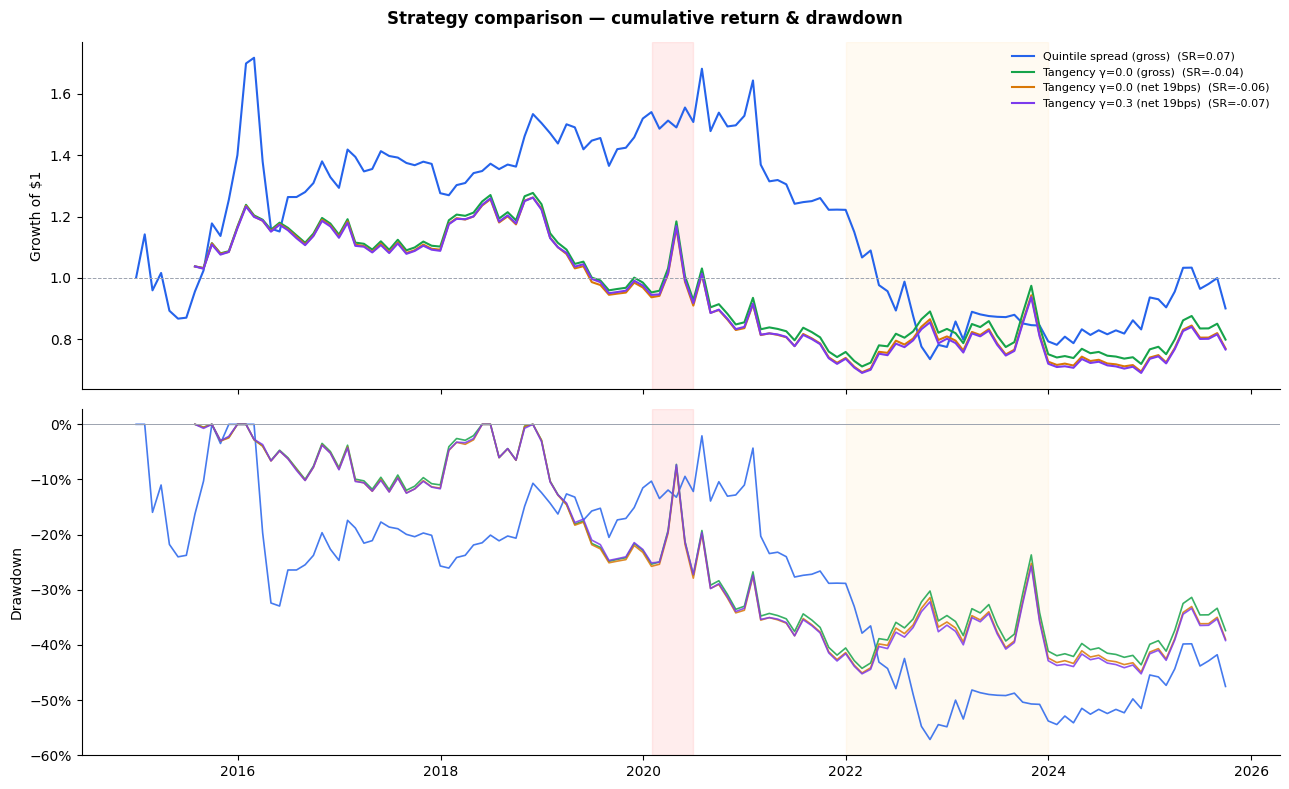

Saved → outputs/backtest/fig5_strategy_comparison.png


In [10]:
# ── Comparison chart: cumulative returns + drawdowns ─────────────────────────
series = {
    "Quintile spread (gross)":   strat["ret"],
    "Tangency γ=0.0 (gross)":    t0["ret_gross"],
    "Tangency γ=0.0 (net 19bps)":t0["ret_net"],
    "Tangency γ=0.3 (net 19bps)":t3["ret_net"],
}
colors = ["#2563EB", "#16A34A", "#D97706", "#7C3AED"]

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
fig.suptitle("Strategy comparison — cumulative return & drawdown",
             fontsize=12, fontweight="bold")

for (label, r), color in zip(series.items(), colors):
    r = r.dropna()
    cum = (1 + r).cumprod()
    dd  = (cum - cum.cummax()) / cum.cummax()
    sr  = float(perf_stats(r)["Sharpe"])
    axes[0].plot(cum.index, cum.values, lw=1.5, color=color,
                 label=f"{label}  (SR={sr:.2f})")
    axes[1].plot(dd.index, dd.values, lw=1.2, color=color, alpha=0.85)

axes[0].axhline(1, color="#9CA3AF", lw=0.7, linestyle="--")
axes[0].set_ylabel("Growth of $1")
axes[0].legend(fontsize=8, frameon=False)
axes[0].spines[["top", "right"]].set_visible(False)

axes[1].axhline(0, color="#9CA3AF", lw=0.7)
axes[1].set_ylabel("Drawdown")
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(xmax=1, decimals=0))
axes[1].spines[["top", "right"]].set_visible(False)

for ax in axes:
    ax.axvspan(pd.Timestamp("2020-02-01"), pd.Timestamp("2020-06-30"),
               alpha=0.07, color="red")
    ax.axvspan(pd.Timestamp("2022-01-01"), pd.Timestamp("2023-12-31"),
               alpha=0.05, color="orange")

plt.tight_layout()
plt.savefig(bt_dir / "fig5_strategy_comparison.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved → outputs/backtest/fig5_strategy_comparison.png")